# Heartbeat PCG Classification -- 2D CNN Training (Colab / GPU)

**What this notebook does:** trains a 2D CNN on log-mel spectrograms of your heart-sound chunks, using on-the-fly augmentation (so no pre-duplicated/augmented files needed) and `class_weight` to handle the natural class imbalance.

**Before you start, upload to Colab (see Section 1):**
- `split_dataset/` (train, val, test folders -- from your local pipeline, unaugmented)
- `noise_clips/` (your recorded ESP32 noise .wav files)

**You do NOT need to upload:** `spectrogram_utils.py`, `augmentation_utils.py`, `train_data_generator.py` -- this notebook writes those itself in Section 2, so there's nothing to keep in sync manually.


## 0. Check GPU is active

Runtime -> Change runtime type -> GPU, before running this.

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Get your data into Colab

**Recommended: zip `split_dataset/` and `noise_clips/` together on your PC first**, then upload the single zip here -- much faster and more reliable than uploading thousands of individual files.

Option A (upload a zip directly to this session -- fastest for one-off runs):

In [2]:
from google.colab import files
uploaded = files.upload()  # select your zip file, e.g. heart_project_data.zip
ZIP_NAME = list(uploaded.keys())[0]
print("Uploaded:", ZIP_NAME)

IndexError: list index out of range

Option B (Google Drive -- better if you'll come back to this over multiple sessions):

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
ZIP_NAME = "/content/drive/MyDrive/heart_project/heart_project_data.zip"  # adjust path

In [6]:
import zipfile, os

EXTRACT_DIR = "/content/heart_project"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

# Auto-detect split_dataset/ and noise_clips/ wherever they actually
# landed -- handles the common case where the zip has an extra top-level
# folder (e.g. you zipped "my_folder" itself instead of its contents).
found = False
for root, dirs, files in os.walk(EXTRACT_DIR):
    if 'split_dataset' in dirs and 'noise_clips' in dirs:
        os.chdir(root)
        found = True
        break

if not found:
    print("WARNING: could not find split_dataset/ and noise_clips/ together "
          "in the extracted zip. Run: !find /content/heart_project -maxdepth 3")
    print("Then manually os.chdir() to the correct folder before continuing.")
else:
    print("Working directory:", os.getcwd())
    print("Contents:", os.listdir())

Working directory: /content/heart_project/heart_project_data
Contents: ['split_dataset', 'noise_clips']


Sanity check -- confirm the expected folders are actually there before going further:

In [7]:
for expected in ["split_dataset/train", "split_dataset/val", "split_dataset/test", "noise_clips"]:
    exists = os.path.isdir(expected)
    print(f"{expected}: {'OK' if exists else 'MISSING'}")

split_dataset/train: OK
split_dataset/val: OK
split_dataset/test: OK
noise_clips: OK


## 2. Write the shared utility modules

These are written directly into this Colab session -- identical to the versions you're using on your PC, so nothing can drift out of sync. Run these three cells once per session.

In [8]:
%%writefile spectrogram_utils.py
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

# --- SHARED CONFIG -- keep everything in the project pointed at this file ---
TARGET_SR = 16000
CHUNK_DURATION = 3          # seconds, matches step 1 chunking
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64
FMAX = 800                  # PCG diagnostic content lives under ~600-800Hz

EXPECTED_SAMPLES = TARGET_SR * CHUNK_DURATION
N_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH

# Heart sound diagnostic content lives in ~20-800Hz. Filtering this
# consistently on EVERY signal (real chunks AND noise clips, before any
# augmentation) removes clearly out-of-band noise/hiss/drift for free.
# It does NOT remove noise that overlaps this band (voices, rumble, fabric
# rustle) -- that's what noise-mixing augmentation is for. The two are
# complementary, not redundant.
BANDPASS_LOW_HZ = 20
BANDPASS_HIGH_HZ = 800
BANDPASS_ORDER = 4

_bandpass_sos_cache = {}

# --- Despike settings ---
# Targets isolated, single-sample-to-a-few-sample digital glitches (an
# instantaneous jump to near full-scale with quiet neighbors on both
# sides) -- distinct from genuine sustained loud/clipped audio, which
# spans many consecutive samples with a smooth attack/decay and is left
# untouched.
DESPIKE_THRESHOLD = 0.95      # near full-scale, in normalized [-1, 1] units
DESPIKE_MAX_RUN = 3           # longer runs are treated as real loud audio
DESPIKE_NEIGHBOR_QUIET = 0.3  # immediate neighbors must be well below this


def despike_glitches(y):
    """Removes isolated near-full-scale digital glitches via linear
    interpolation across the glitch, using its immediate neighbors."""
    y = y.copy()
    abs_y = np.abs(y)
    candidates = np.where(abs_y >= DESPIKE_THRESHOLD)[0]
    if len(candidates) == 0:
        return y

    groups = [[candidates[0]]]
    for idx in candidates[1:]:
        if idx - groups[-1][-1] <= 2:
            groups[-1].append(idx)
        else:
            groups.append([idx])

    for group in groups:
        if len(group) > DESPIKE_MAX_RUN:
            continue  # sustained loud region -- real audio, leave it

        start, end = group[0], group[-1]
        left, right = start - 1, end + 1
        if left < 0 or right >= len(y):
            continue

        # Only treat as a glitch if the audio was genuinely quiet right
        # before and after it -- a real transient's neighbors are still
        # elevated, not near-baseline.
        if abs_y[left] < DESPIKE_NEIGHBOR_QUIET and abs_y[right] < DESPIKE_NEIGHBOR_QUIET:
            y[left:right + 1] = np.linspace(y[left], y[right], right - left + 1)

    return y


def get_bandpass_sos(sr=TARGET_SR):
    """Cached filter coefficients -- avoids recomputing per-call."""
    if sr not in _bandpass_sos_cache:
        nyquist = sr / 2
        low = BANDPASS_LOW_HZ / nyquist
        high = min(BANDPASS_HIGH_HZ / nyquist, 0.99)
        _bandpass_sos_cache[sr] = butter(BANDPASS_ORDER, [low, high],
                                         btype='band', output='sos')
    return _bandpass_sos_cache[sr]


def apply_bandpass(y, sr=TARGET_SR):
    """Zero-phase band-pass filter, applied identically to real audio and
    noise clips alike, so nothing in the pipeline sees unfiltered content."""
    sos = get_bandpass_sos(sr)
    return sosfiltfilt(sos, y).astype(np.float32)


def load_and_filter(filepath, sr=TARGET_SR):
    """The ONE function that should load audio from disk anywhere in this
    project -- loading, resampling, despiking, and band-pass filtering
    all happen here, so training data, noise clips, and visualizations
    can never silently diverge in how they're preprocessed."""
    y, _ = librosa.load(filepath, sr=sr)
    y = despike_glitches(y)       # remove isolated digital glitches first
    return apply_bandpass(y, sr)  # then band-limit to the diagnostic range


def load_fixed_length(source, sr=TARGET_SR, is_array=False):
    """Loads audio (from filepath or an existing array) and forces it to
    exactly CHUNK_DURATION seconds. Re-run this after any augmentation
    that could change length (e.g. time-stretch). Filepath inputs are
    band-pass filtered via load_and_filter; array inputs are assumed to
    already be filtered (e.g. augmented audio that started from a
    filtered source)."""
    if is_array:
        y = source
    else:
        y = load_and_filter(source, sr)

    if len(y) > EXPECTED_SAMPLES:
        y = y[:EXPECTED_SAMPLES]
    elif len(y) < EXPECTED_SAMPLES:
        y = np.pad(y, (0, EXPECTED_SAMPLES - len(y)), mode='constant')
    return y


def audio_to_logmel(y, sr=TARGET_SR):
    """Converts a fixed-length audio array into a fixed-shape log-mel
    spectrogram: (N_MELS, N_FRAMES)."""
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmax=FMAX
    )
    S_dB = librosa.power_to_db(S, ref=np.max)

    if S_dB.shape[1] > N_FRAMES:
        S_dB = S_dB[:, :N_FRAMES]
    elif S_dB.shape[1] < N_FRAMES:
        pad_width = N_FRAMES - S_dB.shape[1]
        S_dB = np.pad(S_dB, ((0, 0), (0, pad_width)), mode='constant',
                      constant_values=S_dB.min())

    return S_dB.astype(np.float32)


def wav_to_logmel(filepath):
    """Convenience wrapper: filepath -> fixed-shape log-mel spectrogram."""
    y = load_fixed_length(filepath)
    return audio_to_logmel(y, TARGET_SR)


Writing spectrogram_utils.py


In [9]:
%%writefile augmentation_utils.py
import os
import glob
import random
import numpy as np
import librosa

from spectrogram_utils import TARGET_SR, apply_bandpass, despike_glitches

# Probabilities are applied to EVERY sample identically, regardless of
# class label. This is what structurally prevents "amount of augmentation"
# from becoming a shortcut the model can use instead of real PCG features.
SAFE_AUG_PROB = 0.5     # chance of a generic transform (stretch/volume/faint noise)
NOISE_PROB = 0.3        # chance of real recorded ESP32 noise, independent of the above
SNR_DB_RANGE = (10, 20)

# Pitch-shifting changes the exact frequency band that defines a murmur --
# left out of the default rotation for that reason.
USE_PITCH_SHIFT = False
PITCH_SHIFT_STEPS = 1

_noise_pool_cache = None


def add_faint_noise(y):
    noise = np.random.normal(0, 0.005 * np.amax(np.abs(y)), len(y))
    return y + noise


def fix_length(y, target_length):
    if len(y) > target_length:
        return y[:target_length]
    elif len(y) < target_length:
        return np.pad(y, (0, target_length - len(y)), mode='constant')
    return y


def safe_augment(y, sr):
    """One randomly chosen generic transform -- never real recorded noise."""
    target_length = len(y)
    methods = ["stretch", "volume", "faint_noise"]
    if USE_PITCH_SHIFT:
        methods.append("pitch")
    method = random.choice(methods)

    if method == "stretch":
        rate = np.random.uniform(0.93, 1.07)
        return fix_length(librosa.effects.time_stretch(y, rate=rate), target_length)
    elif method == "volume":
        scale = np.random.uniform(0.7, 1.3)
        return np.clip(y * scale, -1.0, 1.0)
    elif method == "faint_noise":
        return add_faint_noise(y)
    else:
        return librosa.effects.pitch_shift(y, sr=sr, n_steps=PITCH_SHIFT_STEPS)


def load_noise_pool(noise_dir="noise_clips", target_sr=TARGET_SR):
    """Loads and caches your recorded ESP32 noise clips into one pool."""
    global _noise_pool_cache
    if _noise_pool_cache is not None:
        return _noise_pool_cache

    files = glob.glob(os.path.join(noise_dir, "*.wav"))
    if not files:
        return None

    pool = [apply_bandpass(despike_glitches(librosa.load(f, sr=target_sr, mono=True)[0]), target_sr)
            for f in files]
    _noise_pool_cache = np.concatenate(pool)
    return _noise_pool_cache


def get_noise_segment(noise_pool, num_samples):
    if len(noise_pool) < num_samples:
        repeats = int(np.ceil(num_samples / len(noise_pool)))
        noise_pool = np.tile(noise_pool, repeats)
    start = np.random.randint(0, len(noise_pool) - num_samples + 1)
    return noise_pool[start:start + num_samples]


def mix_at_snr(signal, noise, snr_db):
    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    if noise_power == 0:
        return signal
    target_noise_power = signal_power / (10 ** (snr_db / 10))
    scale = np.sqrt(target_noise_power / noise_power)
    mixed = signal + noise * scale
    max_val = np.max(np.abs(mixed))
    if max_val > 1.0:
        mixed = mixed / max_val
    return mixed


def apply_random_augmentation(y, sr, noise_pool=None):
    """The ONE function used everywhere augmentation happens -- training
    generator and visualizations both call this, so behavior can never
    silently diverge between what you see and what the model trains on."""
    if random.random() < SAFE_AUG_PROB:
        y = safe_augment(y, sr)
    if noise_pool is not None and random.random() < NOISE_PROB:
        snr_db = np.random.uniform(*SNR_DB_RANGE)
        noise_seg = get_noise_segment(noise_pool, len(y))
        y = mix_at_snr(y, noise_seg, snr_db)
    return y


Writing augmentation_utils.py


In [10]:
%%writefile train_data_generator.py
import os
import numpy as np
import librosa
from tensorflow.keras.utils import Sequence

from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool

TRAIN_DIR = "split_dataset/train"      # raw, unbalanced, unaugmented on disk
CLASSES = ["Normal", "Murmur", "Extra_Systole", "Artifact"]


class PCGSequence(Sequence):
    """Yields (spectrogram_batch, label_batch). With augment=True, every
    sample -- regardless of class -- has the same chance of being time
    -stretched, volume-jittered, or noise-mixed. Nothing here branches on
    class label, by design."""

    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:
                              (batch_idx + 1) * self.batch_size]
        X, y = [], []

        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)

            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                # time-stretch can change length -- re-fix before spectrogram
                audio = load_fixed_length(audio, is_array=True)

            spec = audio_to_logmel(audio, TARGET_SR)
            X.append(spec)
            y.append(label)

        X = np.array(X, dtype=np.float32)[..., np.newaxis]
        y = np.array(y, dtype=np.int64)
        return X, y


def compute_class_weights():
    """Since the train split on disk is NOT balanced (we balance via
    class_weight instead of file duplication), pass this dict to
    model.fit(..., class_weight=...)."""
    from sklearn.utils.class_weight import compute_class_weight

    labels = []
    for idx, cls in enumerate(CLASSES):
        class_dir = os.path.join(TRAIN_DIR, cls)
        n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
        labels += [idx] * n

    labels = np.array(labels)
    weights = compute_class_weight(class_weight="balanced",
                                    classes=np.arange(len(CLASSES)), y=labels)
    return {i: w for i, w in enumerate(weights)}


if __name__ == "__main__":
    # Quick sanity check
    seq = PCGSequence(batch_size=8, augment=True)
    X, y = seq[0]
    print(f"Batch shape: {X.shape}, labels: {y}")
    print(f"Class weights: {compute_class_weights()}")


Writing train_data_generator.py


## 3. Import the modules and sanity-check the training generator

In [11]:
from spectrogram_utils import N_MELS, N_FRAMES
from train_data_generator import PCGSequence, compute_class_weights, CLASSES
from spectrogram_utils import load_and_filter

# Quick sanity check -- pulls one real batch through the full live pipeline
sanity_gen = PCGSequence(batch_size=8, augment=True)
X_batch, y_batch = sanity_gen[0]
print("Batch shape:", X_batch.shape)   # expect (8, 64, 188, 1)
print("Labels in batch:", y_batch)

class_weights = compute_class_weights()
print("Class weights (train split, imbalance-aware):", class_weights)

Batch shape: (8, 64, 188, 1)
Labels in batch: [1 3 0 1 0 0 3 0]
Class weights (train split, imbalance-aware): {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(3.6674311926605503), 3: np.float64(2.3794642857142856)}


## 4. Build static val/test spectrogram arrays

val/test are never augmented, so we only need to build these once per session.

In [12]:
import numpy as np
from spectrogram_utils import wav_to_logmel

def build_split(split_dir, split_name):
    print(f"Processing '{split_name}' split from '{split_dir}'...")
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files)} files")
        for f in files:
            spec = wav_to_logmel(os.path.join(class_dir, f))
            X.append(spec)
            y.append(class_idx)
    X = np.array(X, dtype=np.float32)[..., np.newaxis]
    y = np.array(y, dtype=np.int64)
    print(f"  '{split_name}' shape: X={X.shape}, y={y.shape}")
    return X, y

X_val, y_val = build_split("split_dataset/val", "val")
X_test, y_test = build_split("split_dataset/test", "test")

Processing 'val' split from 'split_dataset/val'...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
  'val' shape: X=(342, 64, 188, 1), y=(342,)
Processing 'test' split from 'split_dataset/test'...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files
  'test' shape: X=(378, 64, 188, 1), y=(378,)


## 4.5 Data Exploration & Visualization

This section is for you (and your supervisor) to actually *see* the pipeline
working: dataset stats, class balance, sample waveforms/spectrograms before
and after live augmentation, and your recorded ESP32 noise clips -- including
audio players so you can listen directly in Colab.

### Dataset summary -- shapes and counts

In [13]:
import os
from spectrogram_utils import TARGET_SR, CHUNK_DURATION

INPUT_SHAPE = (N_MELS, N_FRAMES, 1)   # (64, 188, 1) -- defined here so later cells can reuse it

def count_wavs(split_dir):
    counts = {}
    for cls in CLASSES:
        class_dir = os.path.join(split_dir, cls)
        if os.path.isdir(class_dir):
            counts[cls] = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
        else:
            counts[cls] = 0
    return counts

train_counts = count_wavs("split_dataset/train")
val_counts = count_wavs("split_dataset/val")
test_counts = count_wavs("split_dataset/test")
noise_files = [f for f in os.listdir("noise_clips") if f.endswith(".wav")]

print("=" * 55)
print(" DATASET SUMMARY")
print("=" * 55)
print(f"Sample rate:        {TARGET_SR} Hz")
print(f"Chunk duration:     {CHUNK_DURATION}s")
print(f"Spectrogram shape:  ({N_MELS}, {N_FRAMES})  -- (n_mels, n_frames)")
print(f"Model input shape:  {INPUT_SHAPE}")
print(f"Classes:            {CLASSES}")
print()
print(f"{'Class':<15}{'Train':>8}{'Val':>8}{'Test':>8}{'Total':>8}")
for cls in CLASSES:
    total = train_counts[cls] + val_counts[cls] + test_counts[cls]
    print(f"{cls:<15}{train_counts[cls]:>8}{val_counts[cls]:>8}{test_counts[cls]:>8}{total:>8}")
print("-" * 55)
print(f"{'TOTAL':<15}{sum(train_counts.values()):>8}{sum(val_counts.values()):>8}"
      f"{sum(test_counts.values()):>8}{sum(train_counts.values())+sum(val_counts.values())+sum(test_counts.values()):>8}")
print()
print(f"Class weights (for training):  {class_weights}")
print(f"Recorded noise clips:          {len(noise_files)} files -> {noise_files}")
print(f"X_val shape:  {X_val.shape}   y_val shape:  {y_val.shape}")
print(f"X_test shape: {X_test.shape}  y_test shape: {y_test.shape}")
print("=" * 55)

 DATASET SUMMARY
Sample rate:        16000 Hz
Chunk duration:     3s
Spectrogram shape:  (64, 188)  -- (n_mels, n_frames)
Model input shape:  (64, 188, 1)
Classes:            ['Normal', 'Murmur', 'Extra_Systole', 'Artifact']

Class             Train     Val    Test   Total
Normal              893     184     242    1319
Murmur              429      93      84     606
Extra_Systole       109      29      16     154
Artifact            168      36      36     240
-------------------------------------------------------
TOTAL              1599     342     378    2319

Class weights (for training):  {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(3.6674311926605503), 3: np.float64(2.3794642857142856)}
Recorded noise clips:          8 files -> ['noise_clip_ncb.wav', 'noise_clip_fe.wav', 'noise_clip_dhm.wav', 'noise_clip_ncb2.wav', 'noise_clip_tgb.wav', 'noise_clip_clf.wav', 'noise_clip_ambn.wav', 'wifi_test_recording_slenit_noise_ap.wav']
X_val shape:  (3

### Class distribution across splits

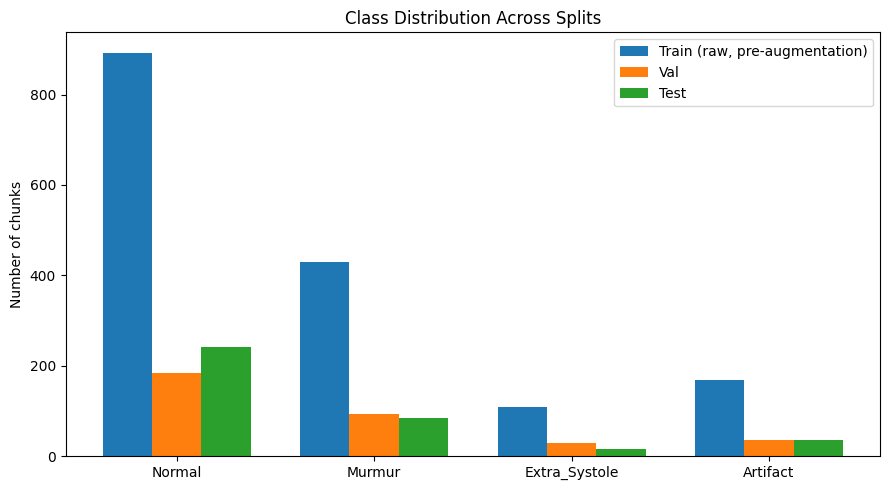

In [14]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(CLASSES))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width, [train_counts[c] for c in CLASSES], width, label='Train (raw, pre-augmentation)')
ax.bar(x,          [val_counts[c] for c in CLASSES],   width, label='Val')
ax.bar(x + width,  [test_counts[c] for c in CLASSES],  width, label='Test')

ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel("Number of chunks")
ax.set_title("Class Distribution Across Splits")
ax.legend()
plt.tight_layout()
plt.show()

### Band-pass filter -- frequency response and effect

Every audio file in this pipeline is band-pass filtered (20-800Hz) at load time via `load_and_filter()`. Two checks here: what the filter itself looks like in the frequency domain, and what it actually does to a real sample's power spectrum before vs. after.

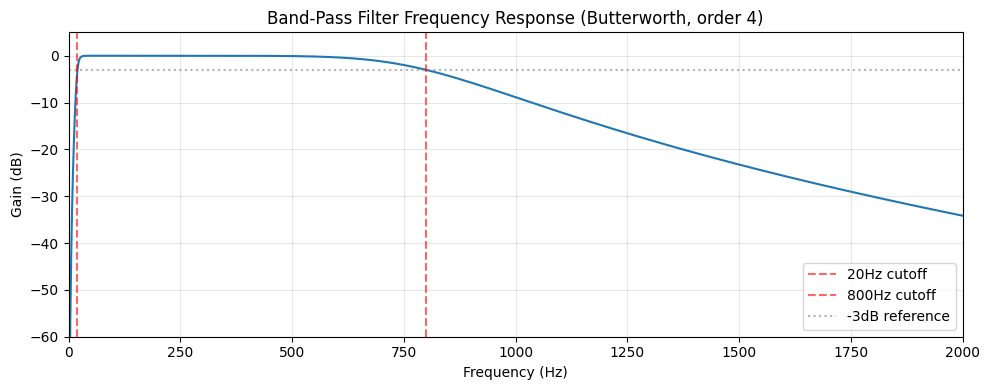

In [15]:
from spectrogram_utils import get_bandpass_sos, apply_bandpass, BANDPASS_LOW_HZ, BANDPASS_HIGH_HZ
from scipy.signal import sosfreqz

sos = get_bandpass_sos(TARGET_SR)
w, h = sosfreqz(sos, worN=4000, fs=TARGET_SR)
mag_db = 20 * np.log10(np.maximum(np.abs(h), 1e-10))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(w, mag_db, color='#1f77b4')
ax.axvline(BANDPASS_LOW_HZ, color='red', linestyle='--', alpha=0.6, label=f'{BANDPASS_LOW_HZ}Hz cutoff')
ax.axvline(BANDPASS_HIGH_HZ, color='red', linestyle='--', alpha=0.6, label=f'{BANDPASS_HIGH_HZ}Hz cutoff')
ax.axhline(-3, color='gray', linestyle=':', alpha=0.6, label='-3dB reference')
ax.set_xlim(0, 2000)
ax.set_ylim(-60, 5)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Gain (dB)')
ax.set_title('Band-Pass Filter Frequency Response (Butterworth, order 4)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

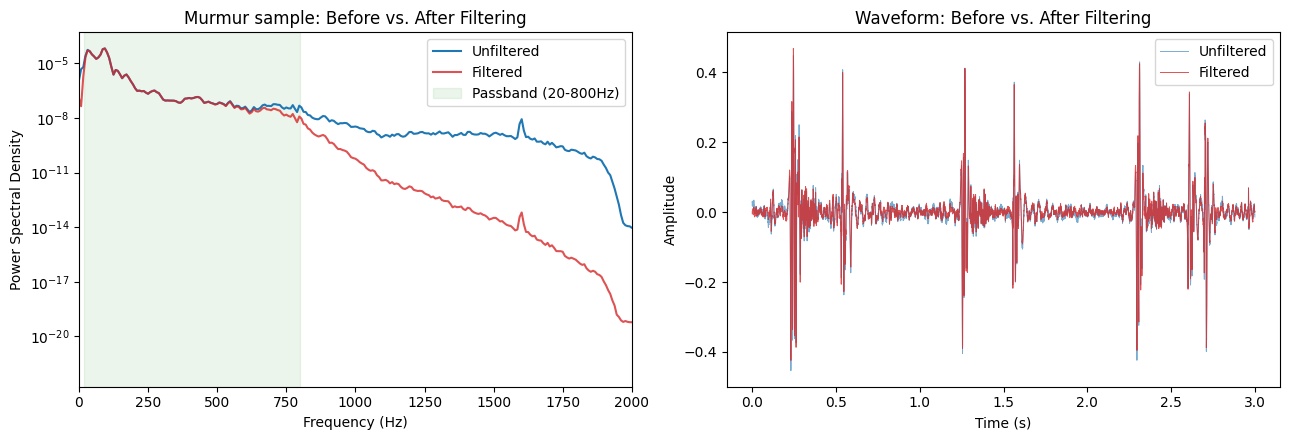

Fraction of total signal power removed by filtering: 4.2%


In [16]:
import librosa
from scipy.signal import welch

sample_class = 'Murmur'
sample_dir = os.path.join('split_dataset/train', sample_class)
sample_file = sorted(os.listdir(sample_dir))[0]
sample_path = os.path.join(sample_dir, sample_file)

y_unfiltered, _ = librosa.load(sample_path, sr=TARGET_SR)
y_filtered = apply_bandpass(y_unfiltered, TARGET_SR)

freqs_u, psd_u = welch(y_unfiltered, fs=TARGET_SR, nperseg=2048)
freqs_f, psd_f = welch(y_filtered, fs=TARGET_SR, nperseg=2048)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogy(freqs_u, psd_u, color='#1f77b4', label='Unfiltered')
axes[0].semilogy(freqs_f, psd_f, color='#d62728', label='Filtered', alpha=0.8)
axes[0].axvspan(BANDPASS_LOW_HZ, BANDPASS_HIGH_HZ, color='green', alpha=0.08, label='Passband (20-800Hz)')
axes[0].set_xlim(0, 2000)
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Power Spectral Density')
axes[0].set_title(f'{sample_class} sample: Before vs. After Filtering')
axes[0].legend()

t = np.arange(len(y_unfiltered)) / TARGET_SR
axes[1].plot(t, y_unfiltered, color='#1f77b4', alpha=0.6, label='Unfiltered', linewidth=0.7)
axes[1].plot(t, y_filtered, color='#d62728', alpha=0.8, label='Filtered', linewidth=0.7)
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title('Waveform: Before vs. After Filtering')
axes[1].legend()

plt.tight_layout()
plt.show()

power_removed = 1 - (np.sum(psd_f) / np.sum(psd_u))
print(f"Fraction of total signal power removed by filtering: {power_removed*100:.1f}%")

### Sample waveforms: raw vs. one live-augmentation draw

Same function (`apply_random_augmentation`) the training generator uses -- this is genuinely what the model sees, not a separate demo version.

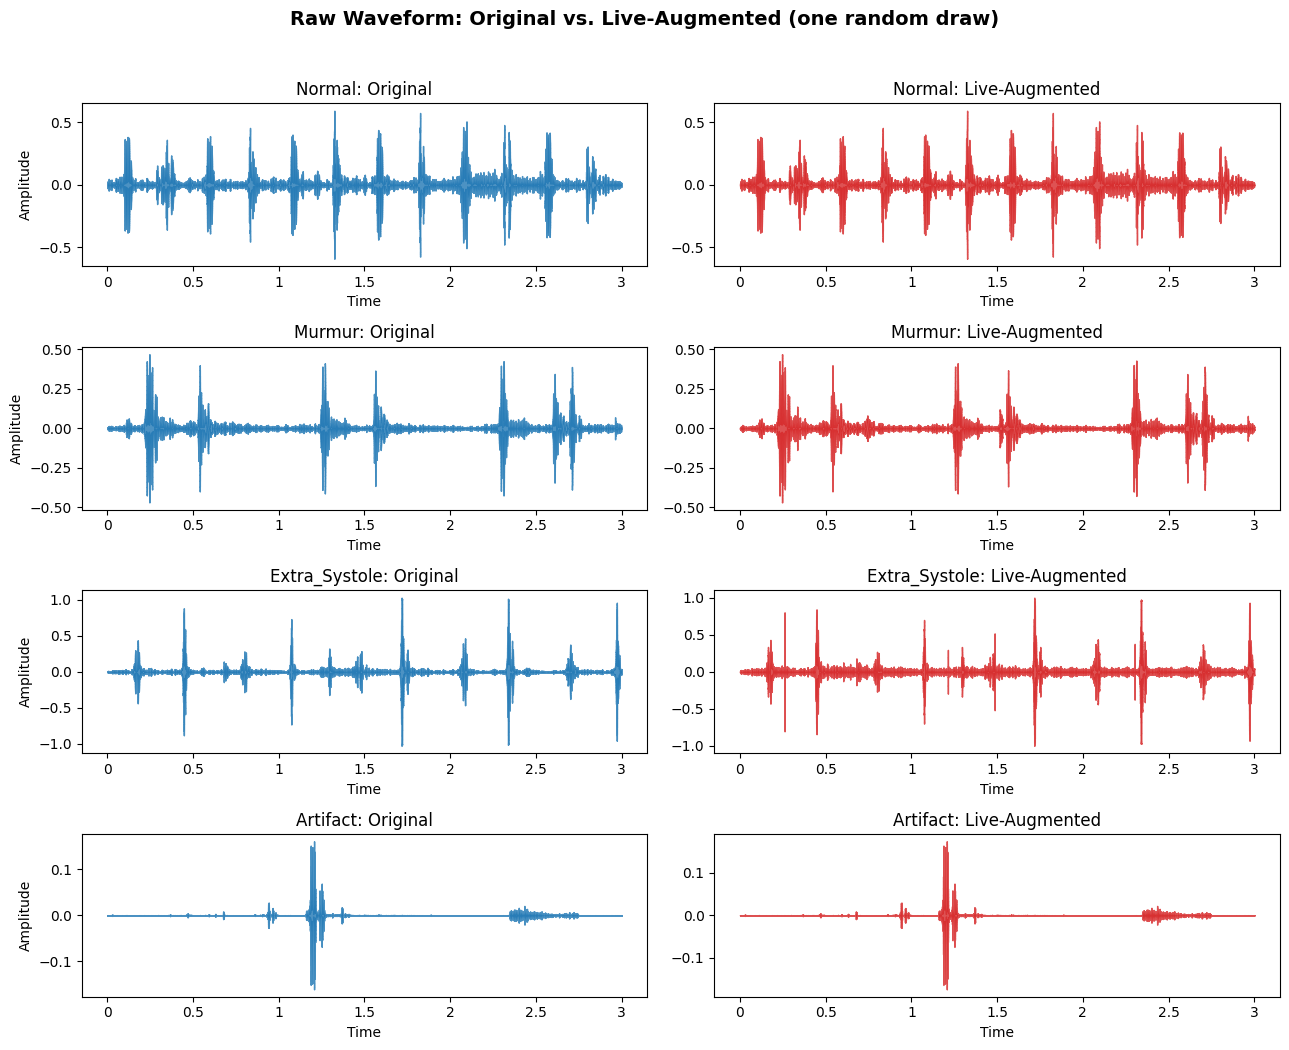

In [17]:
import librosa
import librosa.display
from augmentation_utils import apply_random_augmentation, load_noise_pool

noise_pool_demo = load_noise_pool()

fig, axes = plt.subplots(len(CLASSES), 2, figsize=(13, 11))
fig.suptitle("Raw Waveform: Original vs. Live-Augmented (one random draw)", fontsize=14, fontweight='bold')

for i, cls in enumerate(CLASSES):
    class_dir = os.path.join("split_dataset/train", cls)
    sample_file = sorted(os.listdir(class_dir))[0]
    y_orig = load_and_filter(os.path.join(class_dir, sample_file), TARGET_SR); sr = TARGET_SR
    y_aug = apply_random_augmentation(y_orig.copy(), sr, noise_pool_demo)

    librosa.display.waveshow(y_orig, sr=sr, ax=axes[i, 0], color='#1f77b4', alpha=0.8)
    axes[i, 0].set_title(f"{cls}: Original")
    axes[i, 0].set_ylabel("Amplitude")

    librosa.display.waveshow(y_aug, sr=sr, ax=axes[i, 1], color='#d62728', alpha=0.8)
    axes[i, 1].set_title(f"{cls}: Live-Augmented")

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

### Sample spectrograms: raw vs. live-augmented (the actual model input)

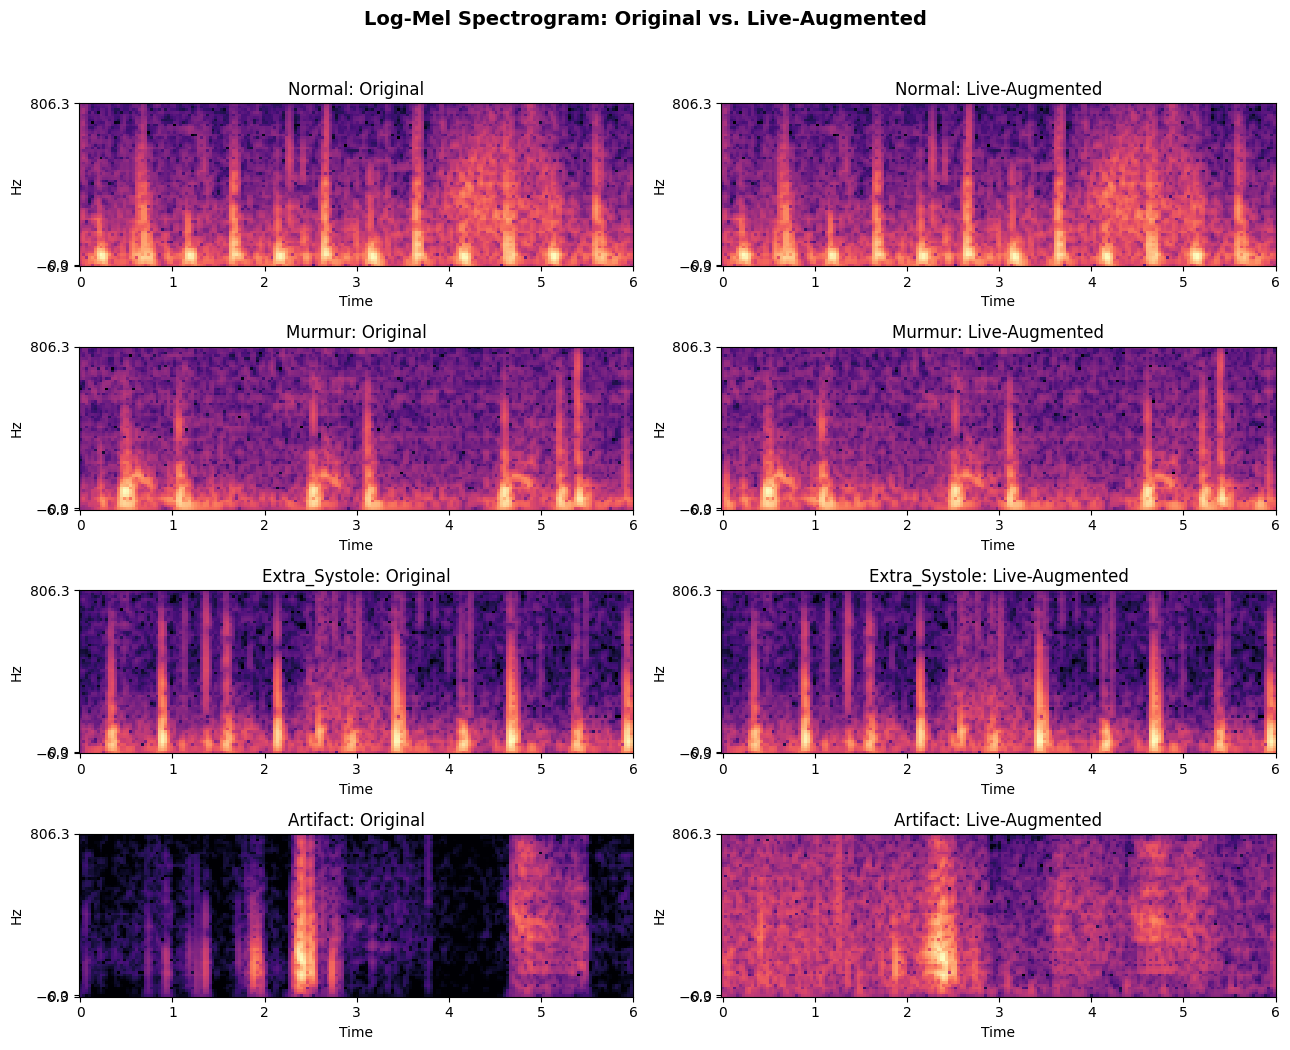

In [18]:
from spectrogram_utils import FMAX, load_fixed_length, audio_to_logmel

fig, axes = plt.subplots(len(CLASSES), 2, figsize=(13, 11))
fig.suptitle("Log-Mel Spectrogram: Original vs. Live-Augmented", fontsize=14, fontweight='bold')

for i, cls in enumerate(CLASSES):
    class_dir = os.path.join("split_dataset/train", cls)
    sample_file = sorted(os.listdir(class_dir))[0]
    y_orig = load_and_filter(os.path.join(class_dir, sample_file), TARGET_SR); sr = TARGET_SR
    y_aug = apply_random_augmentation(y_orig.copy(), sr, noise_pool_demo)
    y_aug = load_fixed_length(y_aug, is_array=True)

    S_orig = audio_to_logmel(y_orig, sr)
    S_aug = audio_to_logmel(y_aug, sr)

    img1 = librosa.display.specshow(S_orig, x_axis='time', y_axis='mel', sr=sr,
                                     fmax=FMAX, ax=axes[i, 0], cmap='magma')
    axes[i, 0].set_title(f"{cls}: Original")

    img2 = librosa.display.specshow(S_aug, x_axis='time', y_axis='mel', sr=sr,
                                     fmax=FMAX, ax=axes[i, 1], cmap='magma')
    axes[i, 1].set_title(f"{cls}: Live-Augmented")

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

### Your recorded ESP32 noise clips

Waveforms of each recorded clip, plus audio players so you (or your supervisor) can literally listen to them here in Colab.

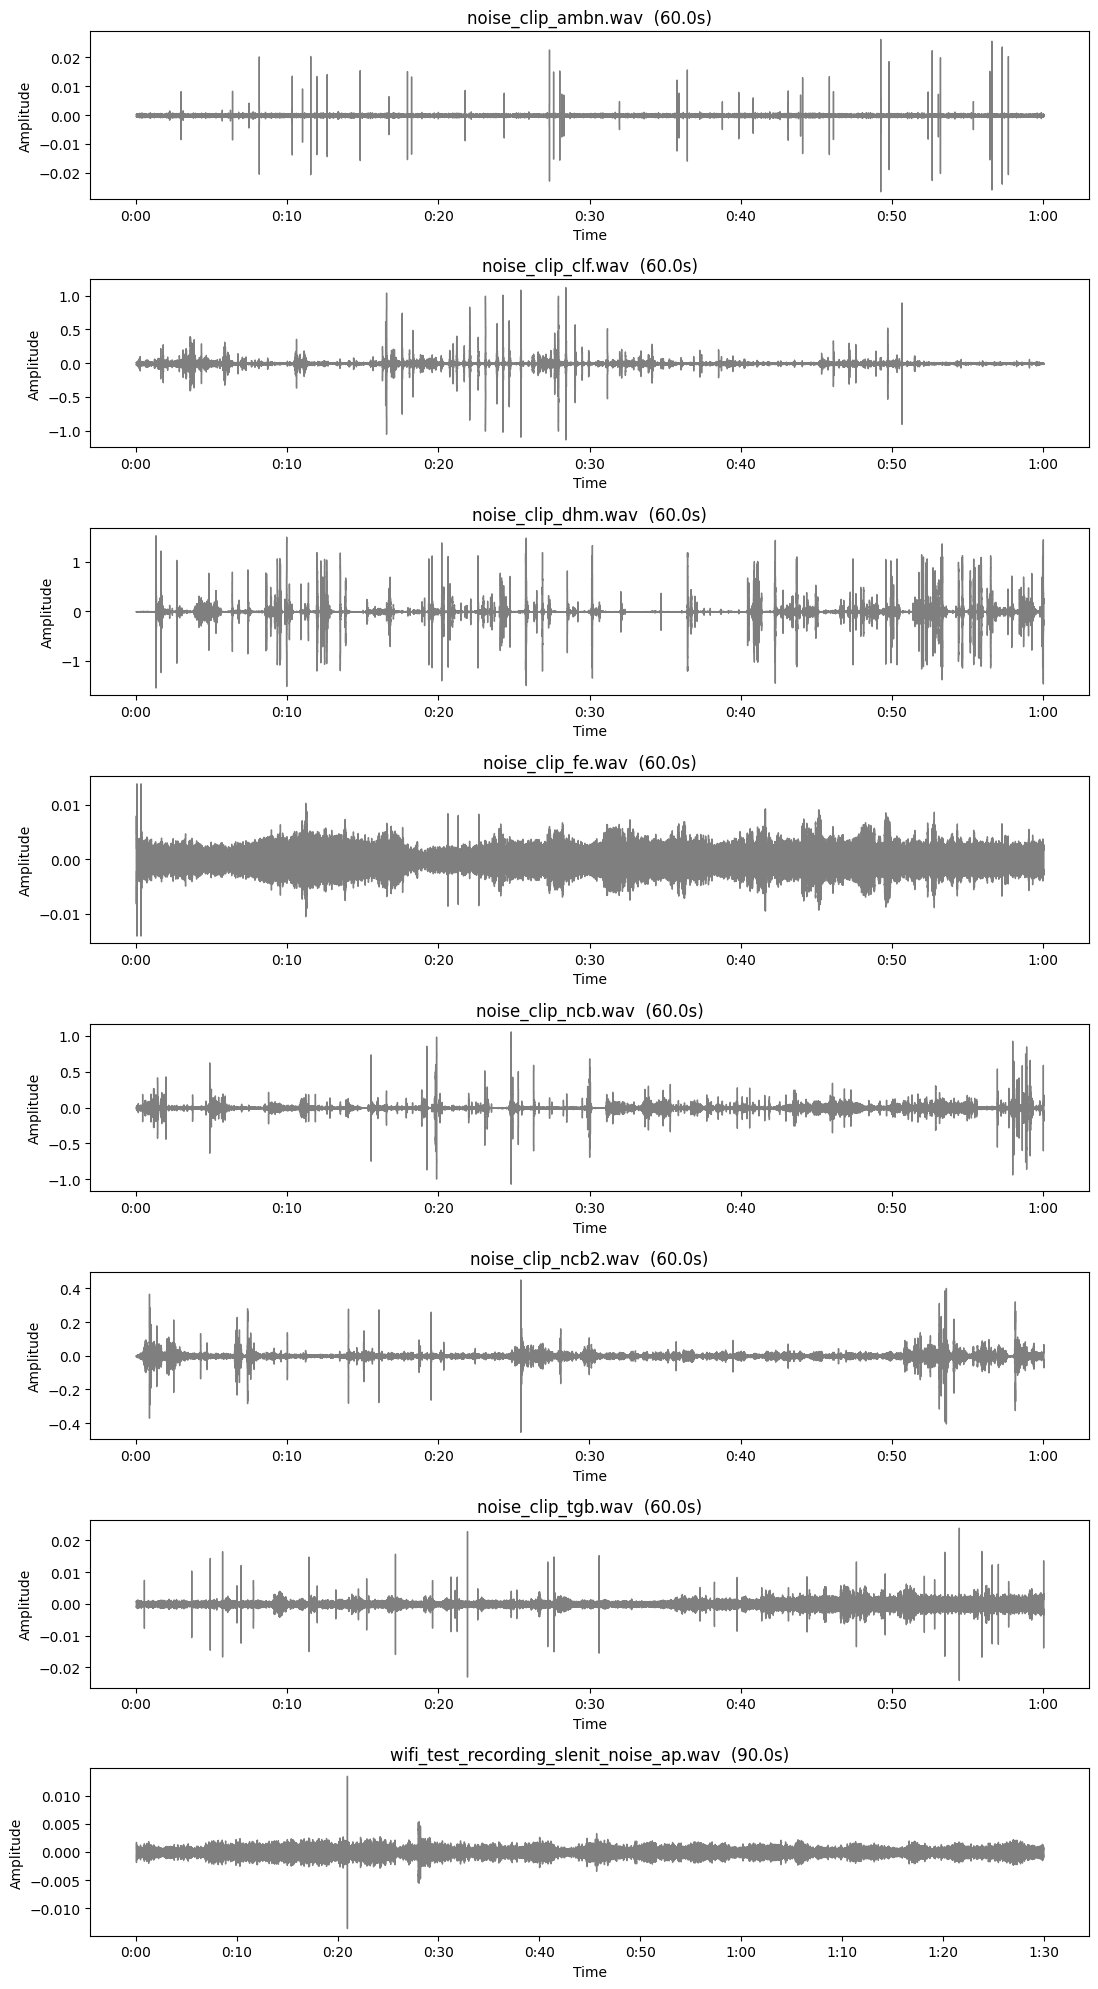

noise_clip_ambn.wav


noise_clip_clf.wav


noise_clip_dhm.wav


noise_clip_fe.wav


noise_clip_ncb.wav


noise_clip_ncb2.wav


noise_clip_tgb.wav


wifi_test_recording_slenit_noise_ap.wav


In [19]:
from IPython.display import Audio, display

fig, axes = plt.subplots(len(noise_files), 1, figsize=(11, 2.5 * len(noise_files)))
if len(noise_files) == 1:
    axes = [axes]

for i, fname in enumerate(sorted(noise_files)):
    y_noise = load_and_filter(os.path.join("noise_clips", fname), TARGET_SR); sr = TARGET_SR
    librosa.display.waveshow(y_noise, sr=sr, ax=axes[i], color='#7f7f7f')
    axes[i].set_title(f"{fname}  ({len(y_noise)/sr:.1f}s)")
    axes[i].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

for fname in sorted(noise_files):
    print(fname)
    display(Audio(os.path.join("noise_clips", fname)))

### Listen to a few heartbeat samples (optional, nice for a supervisor demo)

Plays one original chunk per class, plus one live-augmented version, directly in the notebook.

In [20]:
for cls in CLASSES:
    class_dir = os.path.join("split_dataset/train", cls)
    sample_file = sorted(os.listdir(class_dir))[0]
    y_orig = load_and_filter(os.path.join(class_dir, sample_file), TARGET_SR); sr = TARGET_SR
    y_aug = apply_random_augmentation(y_orig.copy(), sr, noise_pool_demo)

    print(f"--- {cls}: original ---")
    display(Audio(y_orig, rate=sr))
    print(f"--- {cls}: live-augmented ---")
    display(Audio(y_aug, rate=sr))

--- Normal: original ---


--- Normal: live-augmented ---


--- Murmur: original ---


--- Murmur: live-augmented ---


--- Extra_Systole: original ---


--- Extra_Systole: live-augmented ---


--- Artifact: original ---


--- Artifact: live-augmented ---


### What an actual training batch looks like

Pulls one real batch straight out of `PCGSequence` (with augmentation on) and displays it as a grid -- this is literally the tensor the model trains on each step.

Batch tensor shape: (8, 64, 188, 1)  dtype: float32


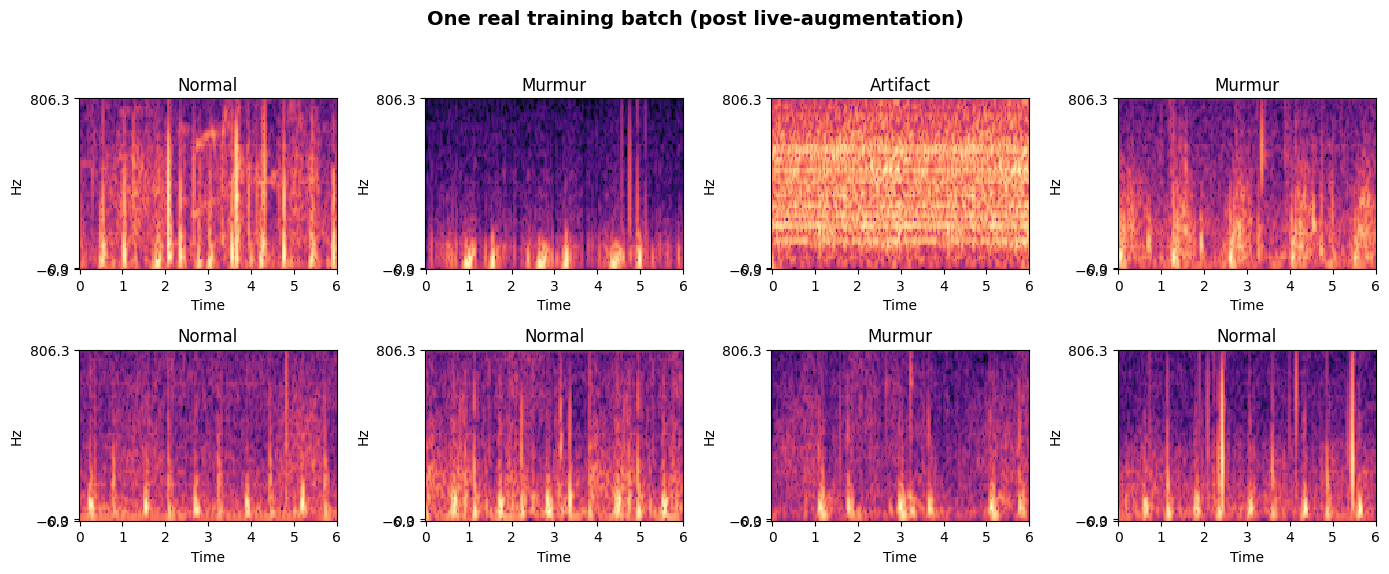

In [21]:
from spectrogram_utils import FMAX

batch_gen = PCGSequence(batch_size=8, augment=True)
X_show, y_show = batch_gen[0]
print("Batch tensor shape:", X_show.shape, " dtype:", X_show.dtype)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()
for i in range(8):
    librosa.display.specshow(X_show[i, :, :, 0], x_axis='time', y_axis='mel',
                             sr=TARGET_SR, fmax=FMAX, ax=axes[i], cmap='magma')
    axes[i].set_title(CLASSES[y_show[i]])
fig.suptitle("One real training batch (post live-augmentation)", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Effective training set size under on-the-fly augmentation

There is no fixed "post-augmentation total" here, unlike the offline
approach -- nothing is duplicated or saved to disk. The raw train count stays
what it is; what changes is how many *randomized views* of that data the
model sees over the course of training. This cell reports both numbers
honestly: what's on disk right now, and what the model will actually be
exposed to once you set your epoch count in Section 7.

In [22]:
PLANNED_EPOCHS = 40   # keep this in sync with the epochs= value in Section 7

steps_per_epoch = len(batch_gen)  # from the PCGSequence built above
raw_train_total = sum(train_counts.values())

print("=" * 55)
print(" TRAINING SET SIZE (on-the-fly augmentation)")
print("=" * 55)
print(f"Raw files on disk (split_dataset/train):  {raw_train_total}")
print(f"  -> {train_counts}")
print(f"Batch size:                                {batch_gen.batch_size}")
print(f"Steps per epoch:                           {steps_per_epoch}")
print(f"Planned epochs:                            {PLANNED_EPOCHS}")
print(f"Total augmented VIEWS the model will see:  "
      f"{steps_per_epoch * batch_gen.batch_size * PLANNED_EPOCHS:,}")
print(f"  (raw_train_total x epochs, roughly -- each epoch reshuffles and")
print(f"   re-augments the same {raw_train_total} files with fresh random draws)")
print()
print(f"Val set size (fixed, never augmented):     {X_val.shape[0]}")
print(f"Test set size (fixed, never augmented):    {X_test.shape[0]}")
print("=" * 55)

 TRAINING SET SIZE (on-the-fly augmentation)
Raw files on disk (split_dataset/train):  1599
  -> {'Normal': 893, 'Murmur': 429, 'Extra_Systole': 109, 'Artifact': 168}
Batch size:                                8
Steps per epoch:                           200
Planned epochs:                            40
Total augmented VIEWS the model will see:  64,000
  (raw_train_total x epochs, roughly -- each epoch reshuffles and
   re-augments the same 1599 files with fresh random draws)

Val set size (fixed, never augmented):     342
Test set size (fixed, never augmented):    378


## 5. Build the 2D CNN

In [23]:
from tensorflow.keras import layers, models

NUM_CLASSES = len(CLASSES)
# INPUT_SHAPE was already defined in the Data Exploration section above

def build_cnn(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(16, (3, 3), padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model

model = build_cnn()
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 188, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 188, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 188, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 94, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 94, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 94, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 94, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 23, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 23, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,420 (111.02 KB)

 Trainable params: 28,068 (109.64 KB)

 Non-trainable params: 352 (1.38 KB)

## 6. Callbacks -- early stopping, LR reduction, checkpointing

In [24]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_pcg_cnn.keras', monitor='val_loss', save_best_only=True),
]

## 7. Train

In [25]:
class_weights = compute_class_weights()  # fresh, unmodified
print(class_weights)  # confirm these are the original values before touching them
class_weights[2] *= 1.3   # apply ONE deliberate, isolated change

{0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(3.6674311926605503), 3: np.float64(2.3794642857142856)}


In [26]:
train_gen = PCGSequence(batch_size=32, shuffle=True, augment=True)

history = model.fit(
    train_gen,
    validation_data=(X_val, y_val),
    epochs=40,
    class_weight=class_weights,
    callbacks=callbacks,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 57s 842ms/step - accuracy: 0.3452 - loss: 1.4060 - val_accuracy: 0.3304 - val_loss: 1.7396 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 32s 636ms/step - accuracy: 0.3959 - loss: 1.1380 - val_accuracy: 0.1228 - val_loss: 1.5580 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 564ms/step - accuracy: 0.4296 - loss: 1.1015 - val_accuracy: 0.1053 - val_loss: 1.5373 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 44s 615ms/step - accuracy: 0.4190 - loss: 1.0515 - val_accuracy: 0.3216 - val_loss: 1.1364 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 628ms/step - accuracy: 0.4916 - loss: 0.9277 - val_accuracy: 0.5848 - val_loss: 1.1372 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 605ms/step - accuracy: 0.4778 - loss: 0.8901 - val_accuracy: 0.2836 - val_loss: 1.2498 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 604ms/step - accuracy: 0.5228 - loss: 0.

## 8. Plot training curves

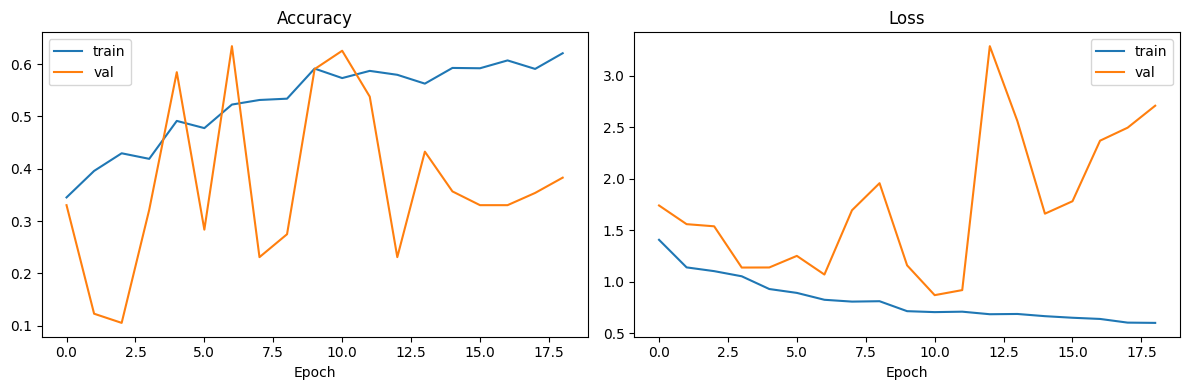

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='val')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='val')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Evaluate on the held-out test set

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.6138 - loss: 0.9592
Test accuracy: 0.6138
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step

Classification report:
               precision    recall  f1-score   support

       Normal       0.74      0.66      0.70       242
       Murmur       1.00      0.35      0.51        84
Extra_Systole       0.14      0.44      0.21        16
     Artifact       0.43      1.00      0.60        36

     accuracy                           0.61       378
    macro avg       0.58      0.61      0.51       378
 weighted avg       0.75      0.61      0.63       378



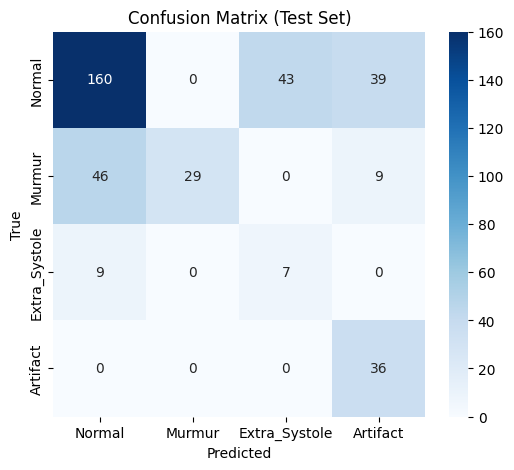

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=CLASSES))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.show()

## 10. Save the trained model

Save to Drive if you mounted it in Section 1, so it survives after this Colab session ends.

In [ ]:
model.save("pcg_cnn_final.keras")
print("Saved to pcg_cnn_final.keras -- download it or copy to your mounted Drive folder.")

# If Drive is mounted:
# import shutil
# shutil.copy("pcg_cnn_final.keras", "/content/drive/MyDrive/heart_project/pcg_cnn_final.keras")

## 11. Export dataset statistics for your paper

Generates a markdown table and a methods-section paragraph using the actual
numbers from this run -- paste directly into your write-up.

In [ ]:
total_train = sum(train_counts.values())
total_val = sum(val_counts.values())
total_test = sum(test_counts.values())
grand_total = total_train + total_val + total_test

table_lines = [
    "| Class | Train | Val | Test | Total |",
    "|---|---|---|---|---|",
]
for cls in CLASSES:
    row_total = train_counts[cls] + val_counts[cls] + test_counts[cls]
    table_lines.append(f"| {cls.replace('_', ' ')} | {train_counts[cls]} | "
                       f"{val_counts[cls]} | {test_counts[cls]} | {row_total} |")
table_lines.append(f"| **Total** | **{total_train}** | **{total_val}** | "
                   f"**{total_test}** | **{grand_total}** |")

markdown_table = "\n".join(table_lines)

paragraph = f'''Heart sound recordings were obtained from the PASCAL Classifying Heart
Sounds Challenge dataset (Bentley et al., 2011). Recordings were segmented
into fixed {CHUNK_DURATION}-second windows using a 50% overlap sliding
window, resampled to {TARGET_SR}Hz, and windows containing more than 50%
silence were discarded, yielding {grand_total} total chunks across
{len(CLASSES)} classes. The dataset was split {int(total_train/grand_total*100)}/{int(total_val/grand_total*100)}/{int(total_test/grand_total*100)}
into training, validation, and test sets at the level of original source
recordings (not individual chunks), to prevent chunks derived from the same
recording from appearing in more than one split.

To address class imbalance without duplicating data, class-weighted loss
was used ({class_weights}) in place of oversampling. Training samples were
additionally augmented online: each sample had a 50% probability of a
generic transform (time-stretch, volume scaling, or faint synthetic noise)
and, independently, a 30% probability of being mixed with real ambient
noise recorded through the target hardware (ESP32 with MEMS microphone
coupled to a modified stethoscope) at 10-20dB SNR. Both probabilities were
applied identically regardless of class label. Validation and test sets
were never augmented.'''

print("=" * 70)
print(" MARKDOWN TABLE -- paste into your paper")
print("=" * 70)
print(markdown_table)
print()
print("=" * 70)
print(" METHODS PARAGRAPH -- paste and edit as needed")
print("=" * 70)
print(paragraph)

with open("dataset_report.md", "w") as f:
    f.write("## Dataset Table\n\n" + markdown_table + "\n\n## Methods Paragraph\n\n" + paragraph)
print()
print("Also saved to dataset_report.md")

## 12. Two-Stage Architecture: Binary (Normal vs Abnormal) then Abnormal-Type Classifier

Stage 1 decides Normal vs Abnormal (pooling Murmur+Extra_Systole+Artifact
into one class gives far more training examples per decision than any
single abnormal class had alone). Stage 2 only runs on cases Stage 1
flagged abnormal, and decides which abnormal type. Final evaluation
combines both stages back into the original 4-class problem for a fair,
honest comparison against the single-model baseline.

In [29]:
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.utils import Sequence
from train_data_generator import TRAIN_DIR

# Binary labels for val/test: 0 = Normal, 1 = Abnormal (any of the other 3)
y_val_binary = (y_val > 0).astype(np.int64)
y_test_binary = (y_test > 0).astype(np.int64)

# Fresh binary class weights, computed directly from train folder counts
binary_labels = []
for idx, cls in enumerate(CLASSES):
    class_dir = os.path.join(TRAIN_DIR, cls)
    n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
    label = 0 if cls == "Normal" else 1
    binary_labels += [label] * n
binary_labels = np.array(binary_labels)

stage1_class_weights = compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1]), y=binary_labels)
stage1_class_weights = {i: w for i, w in enumerate(stage1_class_weights)}
print("Stage 1 (binary) class weights:", stage1_class_weights)


class BinaryLabelWrapper(Sequence):
    """Wraps an existing PCGSequence and converts its 4-class labels to
    binary (0=Normal, 1=Abnormal), reusing all its loading/augmentation
    logic untouched."""
    def __init__(self, base_sequence):
        self.base = base_sequence

    def __len__(self):
        return len(self.base)

    def on_epoch_end(self):
        self.base.on_epoch_end()

    def __getitem__(self, idx):
        X, y = self.base[idx]
        y_binary = (y > 0).astype(np.int64)
        return X, y_binary


train_gen_stage1 = BinaryLabelWrapper(
    PCGSequence(batch_size=32, shuffle=True, augment=True))

print(f"Stage 1 train batches per epoch: {len(train_gen_stage1)}")

Stage 1 (binary) class weights: {0: np.float64(0.8952967525195968), 1: np.float64(1.1324362606232294)}
Stage 1 train batches per epoch: 50


In [30]:
model_stage1 = build_cnn(num_classes=2)
model_stage1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage1 = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_stage1_binary.keras', monitor='val_loss', save_best_only=True),
]

history_stage1 = model_stage1.fit(
    train_gen_stage1,
    validation_data=(X_val, y_val_binary),
    epochs=40,
    class_weight=stage1_class_weights,
    callbacks=callbacks_stage1,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 46s 693ms/step - accuracy: 0.6223 - loss: 0.7820 - val_accuracy: 0.4561 - val_loss: 1.2572 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 594ms/step - accuracy: 0.6742 - loss: 0.6510 - val_accuracy: 0.4620 - val_loss: 1.4183 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 595ms/step - accuracy: 0.6967 - loss: 0.6201 - val_accuracy: 0.4912 - val_loss: 0.9915 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 569ms/step - accuracy: 0.7048 - loss: 0.5874 - val_accuracy: 0.5263 - val_loss: 0.9314 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 549ms/step - accuracy: 0.7042 - loss: 0.5811 - val_accuracy: 0.6901 - val_loss: 0.6499 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 603ms/step - accuracy: 0.7186 - loss: 0.5619 - val_accuracy: 0.6170 - val_loss: 0.6908 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 593ms/step - accuracy: 0.7305 - loss: 0.

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.7249 - loss: 0.5859
Stage 1 (binary) test accuracy: 0.7249
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step

Stage 1 classification report (Normal vs Abnormal):
              precision    recall  f1-score   support

      Normal       0.76      0.83      0.79       242
    Abnormal       0.64      0.54      0.59       136

    accuracy                           0.72       378
   macro avg       0.70      0.69      0.69       378
weighted avg       0.72      0.72      0.72       378



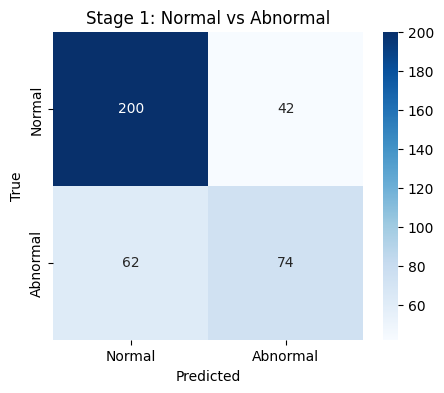

In [31]:
test_loss_s1, test_acc_s1 = model_stage1.evaluate(X_test, y_test_binary)
print(f"Stage 1 (binary) test accuracy: {test_acc_s1:.4f}")

y_pred_s1 = np.argmax(model_stage1.predict(X_test), axis=1)
print("\nStage 1 classification report (Normal vs Abnormal):")
print(classification_report(y_test_binary, y_pred_s1, target_names=["Normal", "Abnormal"]))

cm_s1 = confusion_matrix(y_test_binary, y_pred_s1)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_s1, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Stage 1: Normal vs Abnormal')
plt.show()

In [32]:
from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool

ABNORMAL_CLASSES = ["Murmur", "Extra_Systole", "Artifact"]  # new indices 0,1,2

class AbnormalSequence(Sequence):
    """Same loading/augmentation pipeline as PCGSequence, restricted to
    the 3 abnormal classes only, with fresh 0/1/2 labels."""
    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(ABNORMAL_CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        X, y = [], []
        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                audio = load_fixed_length(audio, is_array=True)
            spec = audio_to_logmel(audio, TARGET_SR)
            X.append(spec)
            y.append(label)
        X = np.array(X, dtype=np.float32)[..., np.newaxis]
        y = np.array(y, dtype=np.int64)
        return X, y


train_gen_stage2 = AbnormalSequence(batch_size=32, shuffle=True, augment=True)
print(f"Stage 2 train batches per epoch: {len(train_gen_stage2)}")

# Fresh stage-2 class weights from train folder counts (abnormal classes only)
stage2_labels = []
for idx, cls in enumerate(ABNORMAL_CLASSES):
    class_dir = os.path.join(TRAIN_DIR, cls)
    n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
    stage2_labels += [idx] * n
stage2_labels = np.array(stage2_labels)

stage2_class_weights = compute_class_weight(
    class_weight="balanced", classes=np.arange(len(ABNORMAL_CLASSES)), y=stage2_labels)
stage2_class_weights = {i: w for i, w in enumerate(stage2_class_weights)}
print("Stage 2 (abnormal-type) class weights:", stage2_class_weights)

# Filter val/test down to abnormal-only, remap original labels {1,2,3} -> {0,1,2}
label_remap = {1: 0, 2: 1, 3: 2}  # Murmur, Extra_Systole, Artifact

val_mask = y_val > 0
X_val_abnormal = X_val[val_mask]
y_val_abnormal = np.array([label_remap[l] for l in y_val[val_mask]])

test_mask = y_test > 0
X_test_abnormal = X_test[test_mask]
y_test_abnormal = np.array([label_remap[l] for l in y_test[test_mask]])

print(f"Stage 2 val samples: {X_val_abnormal.shape[0]}, test samples: {X_test_abnormal.shape[0]}")

Stage 2 train batches per epoch: 23
Stage 2 (abnormal-type) class weights: {0: np.float64(0.5485625485625486), 1: np.float64(2.159021406727829), 2: np.float64(1.4007936507936507)}
Stage 2 val samples: 158, test samples: 136


In [33]:
model_stage2 = build_cnn(num_classes=3)
model_stage2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage2 = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_stage2_abnormal.keras', monitor='val_loss', save_best_only=True),
]

history_stage2 = model_stage2.fit(
    train_gen_stage2,
    validation_data=(X_val_abnormal, y_val_abnormal),
    epochs=40,
    class_weight=stage2_class_weights,
    callbacks=callbacks_stage2,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.4830 - loss: 1.0110 - val_accuracy: 0.2278 - val_loss: 3.2298 - learning_rate: 0.0010
Epoch 2/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 469ms/step - accuracy: 0.5312 - loss: 0.7449 - val_accuracy: 0.2278 - val_loss: 2.0266 - learning_rate: 0.0010
Epoch 3/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 590ms/step - accuracy: 0.5878 - loss: 0.6360 - val_accuracy: 0.6392 - val_loss: 0.9570 - learning_rate: 0.0010
Epoch 4/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 590ms/step - accuracy: 0.6615 - loss: 0.5980 - val_accuracy: 0.2152 - val_loss: 1.6247 - learning_rate: 0.0010
Epoch 5/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 590ms/step - accuracy: 0.6785 - loss: 0.5748 - val_accuracy: 0.2278 - val_loss: 1.8950 - learning_rate: 0.0010
Epoch 6/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 605ms/step - accuracy: 0.6841 - loss: 0.5560 - val_accuracy: 0.2785 - val_loss: 1.1671 - learning_rate: 0.0010
Epoch 7/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 499ms/step - accuracy: 0.7082 - loss: 0.553

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 190ms/step - accuracy: 0.6912 - loss: 0.8916
Stage 2 (abnormal-type) test accuracy: 0.6912
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 214ms/step

Stage 2 classification report (abnormal types only):
               precision    recall  f1-score   support

       Murmur       0.78      0.70      0.74        84
Extra_Systole       0.00      0.00      0.00        16
     Artifact       0.61      0.97      0.75        36

     accuracy                           0.69       136
    macro avg       0.46      0.56      0.50       136
 weighted avg       0.64      0.69      0.65       136



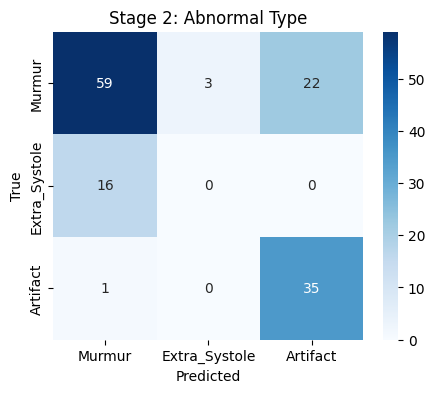

In [34]:
test_loss_s2, test_acc_s2 = model_stage2.evaluate(X_test_abnormal, y_test_abnormal)
print(f"Stage 2 (abnormal-type) test accuracy: {test_acc_s2:.4f}")

y_pred_s2 = np.argmax(model_stage2.predict(X_test_abnormal), axis=1)
print("\nStage 2 classification report (abnormal types only):")
print(classification_report(y_test_abnormal, y_pred_s2, target_names=ABNORMAL_CLASSES))

cm_s2 = confusion_matrix(y_test_abnormal, y_pred_s2)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_s2, annot=True, fmt='d', cmap='Blues',
            xticklabels=ABNORMAL_CLASSES, yticklabels=ABNORMAL_CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Stage 2: Abnormal Type')
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 309ms/step
 TWO-STAGE PIPELINE -- FULL 4-CLASS RESULT
               precision    recall  f1-score   support

       Normal       0.76      0.83      0.79       242
       Murmur       0.52      0.37      0.43        84
Extra_Systole       0.00      0.00      0.00        16
     Artifact       0.76      0.97      0.85        36

     accuracy                           0.70       378
    macro avg       0.51      0.54      0.52       378
 weighted avg       0.68      0.70      0.69       378



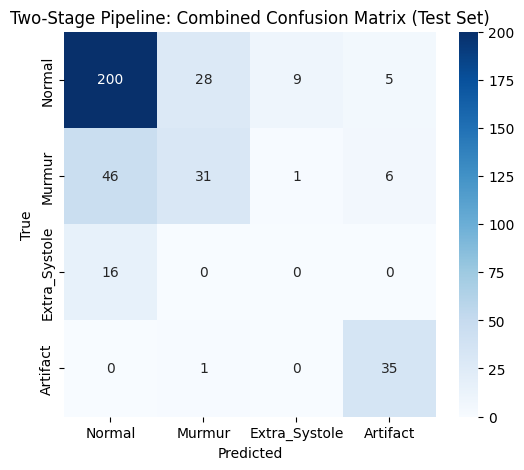


Overall two-stage test accuracy: 0.7037
Compare directly against the single-model baseline's 0.6878.


In [35]:
# Run the full pipeline as it would actually work: Stage 1 decides
# Normal/Abnormal, Stage 2 only runs on what Stage 1 flagged abnormal.
stage1_preds = np.argmax(model_stage1.predict(X_test), axis=1)

final_preds = np.zeros(len(X_test), dtype=int)  # default: Normal (0)
abnormal_indices = np.where(stage1_preds == 1)[0]

if len(abnormal_indices) > 0:
    stage2_preds_sub = np.argmax(model_stage2.predict(X_test[abnormal_indices]), axis=1)
    reverse_map = {0: 1, 1: 2, 2: 3}  # back to original 4-class indices
    for i, idx in enumerate(abnormal_indices):
        final_preds[idx] = reverse_map[stage2_preds_sub[i]]

print("=" * 55)
print(" TWO-STAGE PIPELINE -- FULL 4-CLASS RESULT")
print("=" * 55)
print(classification_report(y_test, final_preds, target_names=CLASSES))

cm_combined = confusion_matrix(y_test, final_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_combined, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Two-Stage Pipeline: Combined Confusion Matrix (Test Set)')
plt.show()

overall_acc = np.mean(final_preds == y_test)
print(f"\nOverall two-stage test accuracy: {overall_acc:.4f}")
print("Compare directly against the single-model baseline's 0.6878.")

## 13. YAMNet Transfer Learning

YAMNet is pretrained on AudioSet (real-world audio, not photographs) --
a much smaller domain gap to PCG than an ImageNet-pretrained CNN. We keep
YAMNet fully frozen (feature extraction only, no fine-tuning) given our
dataset size, and train only a small classifier head on top of its
1024-dim embeddings. YAMNet expects mono 16kHz waveforms, which is
exactly our TARGET_SR -- no resampling needed.

In [36]:
import tensorflow_hub as hub
from train_data_generator import TRAIN_DIR

yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

# Quick sanity check on one real sample
sample_path = os.path.join(TRAIN_DIR, "Normal", sorted(os.listdir(os.path.join(TRAIN_DIR, "Normal")))[0])
sample_audio = load_and_filter(sample_path, TARGET_SR)
sample_audio = load_fixed_length(sample_audio, is_array=True)
waveform = tf.convert_to_tensor(sample_audio, dtype=tf.float32)

scores, embeddings, spectrogram = yamnet_model(waveform)
print("Embeddings shape (num_frames, 1024):", embeddings.shape)
print("This will be mean-pooled over frames to one 1024-dim vector per chunk.")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Embeddings shape (num_frames, 1024): (6, 1024)
This will be mean-pooled over frames to one 1024-dim vector per chunk.


In [37]:
from tensorflow.keras.utils import Sequence
class YamnetEmbeddingSequence(Sequence):
    """Same augmentation pipeline as PCGSequence, but yields mean-pooled
    YAMNet embeddings (1024-dim) instead of mel-spectrograms."""
    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        X, y = [], []
        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                audio = load_fixed_length(audio, is_array=True)

            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            embedding = tf.reduce_mean(embeddings, axis=0).numpy()

            X.append(embedding)
            y.append(label)

        X = np.array(X, dtype=np.float32)
        y = np.array(y, dtype=np.int64)
        return X, y


train_gen_yamnet = YamnetEmbeddingSequence(batch_size=32, shuffle=True, augment=True)
print(f"YAMNet train batches per epoch: {len(train_gen_yamnet)}")

YAMNet train batches per epoch: 50


In [38]:
def build_yamnet_embeddings(split_dir):
    """Precomputes mean-pooled YAMNet embeddings for a never-augmented
    split (val/test), same pattern as the spectrogram build_split earlier."""
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files)} files")
        for f in files:
            audio = load_and_filter(os.path.join(class_dir, f), TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            embedding = tf.reduce_mean(embeddings, axis=0).numpy()
            X.append(embedding)
            y.append(class_idx)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

print("Building val embeddings...")
X_val_yamnet, y_val_yamnet = build_yamnet_embeddings("split_dataset/val")
print("Building test embeddings...")
X_test_yamnet, y_test_yamnet = build_yamnet_embeddings("split_dataset/test")

print(f"\nX_val_yamnet shape: {X_val_yamnet.shape}")
print(f"X_test_yamnet shape: {X_test_yamnet.shape}")

Building val embeddings...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
Building test embeddings...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files

X_val_yamnet shape: (342, 1024)
X_test_yamnet shape: (378, 1024)


In [39]:
from tensorflow.keras import layers, models

def build_yamnet_head(input_dim=1024, num_classes=4):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs)

model_yamnet = build_yamnet_head()
model_yamnet.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_yamnet.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,228 (547.77 KB)

 Trainable params: 139,972 (546.77 KB)

 Non-trainable params: 256 (1.00 KB)

In [40]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks_yamnet = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_head.keras', monitor='val_loss', save_best_only=True),
]

class_weights_yamnet = compute_class_weights()  # fresh, unmodified
class_weights_yamnet[2] *= 0.7   # Extra_Systole: 3.67 -> ~2.57, was overcorrecting
# class_weights_yamnet[2] = 2.7
print("Adjusted YAMNet weights:", class_weights_yamnet)

history_yamnet = model_yamnet.fit(
    train_gen_yamnet,
    validation_data=(X_val_yamnet, y_val_yamnet),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet,
)

Adjusted YAMNet weights: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(2.567201834862385), 3: np.float64(2.3794642857142856)}


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 492ms/step - accuracy: 0.3652 - loss: 1.2552 - val_accuracy: 0.6287 - val_loss: 1.1085 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 411ms/step - accuracy: 0.5228 - loss: 0.9291 - val_accuracy: 0.6199 - val_loss: 1.0645 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 410ms/step - accuracy: 0.5491 - loss: 0.8857 - val_accuracy: 0.4327 - val_loss: 1.0217 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 432ms/step - accuracy: 0.5335 - loss: 0.8144 - val_accuracy: 0.5906 - val_loss: 0.9575 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 415ms/step - accuracy: 0.5797 - loss: 0.7692 - val_accuracy: 0.5731 - val_loss: 0.9267 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 439ms/step - accuracy: 0.5860 - loss: 0.7965 - val_accuracy: 0.5673 - val_loss: 0.9241 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 407ms/step - accuracy: 0.5879 - loss: 0.

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.6852 - loss: 0.8350
YAMNet head test accuracy: 0.6852
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

YAMNet classification report:
               precision    recall  f1-score   support

       Normal       0.86      0.69      0.76       242
       Murmur       0.74      0.61      0.67        84
Extra_Systole       0.15      0.56      0.23        16
     Artifact       0.59      0.92      0.72        36

     accuracy                           0.69       378
    macro avg       0.59      0.69      0.60       378
 weighted avg       0.78      0.69      0.72       378



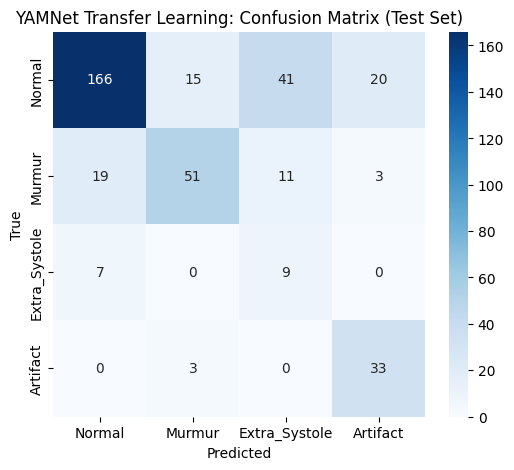


Compare against single-CNN baseline (~0.68) and two-stage pipeline (~0.70-0.72).


In [41]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

test_loss_yn, test_acc_yn = model_yamnet.evaluate(X_test_yamnet, y_test_yamnet)
print(f"YAMNet head test accuracy: {test_acc_yn:.4f}")

y_pred_yn = np.argmax(model_yamnet.predict(X_test_yamnet), axis=1)
print("\nYAMNet classification report:")
print(classification_report(y_test_yamnet, y_pred_yn, target_names=CLASSES))

cm_yn = confusion_matrix(y_test_yamnet, y_pred_yn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_yn, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('YAMNet Transfer Learning: Confusion Matrix (Test Set)')
plt.show()

print("\nCompare against single-CNN baseline (~0.68) and two-stage pipeline (~0.70-0.72).")

```markdown
## 14. Advanced YAMNet: Sequential Modeling (BiGRU / BiLSTM Head)
*Written by Colab AI Assistant*

Instead of collapsing the temporal dimension using mean-pooling, we will preserve the frame sequence returned by YAMNet. We will train a Bidirectional Gated Recurrent Unit (GRU) to learn the rhythmic temporal transitions of the heartbeat segments.

In [42]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import Sequence

class YamnetSequentialSequence(Sequence):
    """
    Yields sequential YAMNet embeddings of shape (batch_size, num_frames, 1024)
    instead of mean-pooling them. This allows our recurrent layers to process sequence dynamics.
    """
    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        X, y = [], []
        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                audio = load_fixed_length(audio, is_array=True)

            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            # Obtain sequential embeddings: (num_frames, 1024)
            _, embeddings, _ = yamnet_model(waveform)
            X.append(embeddings.numpy())
            y.append(label)

        X = np.array(X, dtype=np.float32)
        y = np.array(y, dtype=np.int64)
        return X, y

train_gen_yamnet_seq = YamnetSequentialSequence(batch_size=32, shuffle=True, augment=True)
print(f"YAMNet Sequential train batches per epoch: {len(train_gen_yamnet_seq)}")

YAMNet Sequential train batches per epoch: 50


In [43]:
def build_yamnet_sequential_embeddings(split_dir):
    """Precomputes sequential YAMNet embeddings for validation and test splits."""
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files)} files")
        for f in files:
            audio = load_and_filter(os.path.join(class_dir, f), TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            X.append(embeddings.numpy())
            y.append(class_idx)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

print("Building sequential validation embeddings...")
X_val_yamnet_seq, y_val_yamnet_seq = build_yamnet_sequential_embeddings("split_dataset/val")
print("Building sequential test embeddings...")
X_test_yamnet_seq, y_test_yamnet_seq = build_yamnet_sequential_embeddings("split_dataset/test")

print(f"\nX_val_yamnet_seq shape: {X_val_yamnet_seq.shape} (expect: [342, 6, 1024])")
print(f"X_test_yamnet_seq shape: {X_test_yamnet_seq.shape} (expect: [378, 6, 1024])")

Building sequential validation embeddings...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
Building sequential test embeddings...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files

X_val_yamnet_seq shape: (342, 6, 1024) (expect: [342, 6, 1024])
X_test_yamnet_seq shape: (378, 6, 1024) (expect: [378, 6, 1024])


In [44]:
from tensorflow.keras import layers, models

def build_yamnet_bigru_head(input_shape=(6, 1024), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    # Recurrent sequence analysis
    x = layers.Bidirectional(layers.GRU(64, return_sequences=True))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Bidirectional(layers.GRU(32, return_sequences=False))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Classifier Head
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

model_yamnet_seq = build_yamnet_bigru_head()
model_yamnet_seq.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_yamnet_seq.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 6, 1024)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 6, 128)         │       418,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 6, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 6, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 452,644 (1.73 MB)

 Trainable params: 452,260 (1.73 MB)

 Non-trainable params: 384 (1.50 KB)

In [45]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks_yamnet_seq = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_bigru_head.keras', monitor='val_loss', save_best_only=True),
]

# We will reuse the same class weights since they represent physical training distributions
print("Using Class Weights:", class_weights_yamnet)

history_yamnet_seq = model_yamnet_seq.fit(
    train_gen_yamnet_seq,
    validation_data=(X_val_yamnet_seq, y_val_yamnet_seq),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet_seq,
)

Using Class Weights: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(2.567201834862385), 3: np.float64(2.3794642857142856)}


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 342ms/step - accuracy: 0.3802 - loss: 1.2446 - val_accuracy: 0.5175 - val_loss: 1.0551 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 343ms/step - accuracy: 0.5028 - loss: 0.9629 - val_accuracy: 0.4737 - val_loss: 1.0374 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 345ms/step - accuracy: 0.5228 - loss: 0.9368 - val_accuracy: 0.4825 - val_loss: 0.9745 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 352ms/step - accuracy: 0.5535 - loss: 0.8340 - val_accuracy: 0.6374 - val_loss: 0.8744 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 353ms/step - accuracy: 0.5497 - loss: 0.8069 - val_accuracy: 0.5906 - val_loss: 0.8262 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 343ms/step - accuracy: 0.5547 - loss: 0.7572 - val_accuracy: 0.5263 - val_loss: 0.9707 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 334ms/step - accuracy: 0.5891 - loss: 0.

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6058 - loss: 0.8490
YAMNet Sequential Head test accuracy: 0.6058
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step

YAMNet Sequential BiGRU classification report:
               precision    recall  f1-score   support

       Normal       0.79      0.62      0.70       242
       Murmur       0.56      0.48      0.51        84
Extra_Systole       0.14      0.62      0.22        16
     Artifact       0.68      0.78      0.73        36

     accuracy                           0.61       378
    macro avg       0.54      0.63      0.54       378
 weighted avg       0.70      0.61      0.64       378



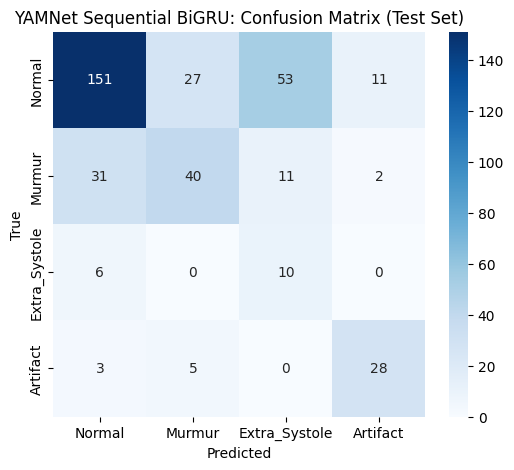

In [46]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

test_loss_ys, test_acc_ys = model_yamnet_seq.evaluate(X_test_yamnet_seq, y_test_yamnet_seq)
print(f"YAMNet Sequential Head test accuracy: {test_acc_ys:.4f}")

y_pred_ys = np.argmax(model_yamnet_seq.predict(X_test_yamnet_seq), axis=1)
print("\nYAMNet Sequential BiGRU classification report:")
print(classification_report(y_test_yamnet_seq, y_pred_ys, target_names=CLASSES))

cm_ys = confusion_matrix(y_test_yamnet_seq, y_pred_ys)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_ys, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('YAMNet Sequential BiGRU: Confusion Matrix (Test Set)')
plt.show()

```markdown
## 15. Regularized YAMNet Sequential Model (Approach 1)
*Written by Colab AI Assistant*

To counter the overfitting observed in the previous run, we reduce the recurrent units to (32, 16) and increase dropout/recurrent dropout to enforce strong regularization on the short 6-frame sequences.
```

In [47]:
from tensorflow.keras import layers, models

def build_yamnet_regularized_bigru_head(input_shape=(6, 1024), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    # Highly regularized, smaller recurrent layers
    x = layers.Bidirectional(layers.GRU(32, return_sequences=True, dropout=0.4, recurrent_dropout=0.4))(inputs)
    x = layers.BatchNormalization()(x)

    x = layers.Bidirectional(layers.GRU(16, return_sequences=False, dropout=0.4, recurrent_dropout=0.4))(x)
    x = layers.BatchNormalization()(x)

    # Classifier Head with higher dropout
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

model_yamnet_seq_regularized = build_yamnet_regularized_bigru_head()
model_yamnet_seq_regularized.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_yamnet_seq_regularized.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 6, 1024)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 6, 64)          │       203,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 32)             │         7,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,580 (830.39 KB)

 Trainable params: 212,388 (829.64 KB)

 Non-trainable params: 192 (768.00 B)

In [48]:
callbacks_yamnet_seq_reg = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_regularized_bigru.keras', monitor='val_loss', save_best_only=True),
]

history_yamnet_seq_reg = model_yamnet_seq_regularized.fit(
    train_gen_yamnet_seq,
    validation_data=(X_val_yamnet_seq, y_val_yamnet_seq),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet_seq_reg,
)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 32s 449ms/step - accuracy: 0.3684 - loss: 1.3348 - val_accuracy: 0.6813 - val_loss: 1.0069 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 397ms/step - accuracy: 0.4396 - loss: 1.0955 - val_accuracy: 0.6696 - val_loss: 0.9449 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 417ms/step - accuracy: 0.4540 - loss: 1.0609 - val_accuracy: 0.5029 - val_loss: 0.9528 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 408ms/step - accuracy: 0.4547 - loss: 0.9865 - val_accuracy: 0.4649 - val_loss: 0.9944 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 416ms/step - accuracy: 0.4916 - loss: 0.9137 - val_accuracy: 0.5614 - val_loss: 0.9056 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 404ms/step - accuracy: 0.5047 - loss: 0.9191 - val_accuracy: 0.6374 - val_loss: 0.8582 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 410ms/step - accuracy: 0.5116 - loss: 0.

In [49]:
test_loss_reg, test_acc_reg = model_yamnet_seq_regularized.evaluate(X_test_yamnet_seq, y_test_yamnet_seq)
print(f"Regularized Sequential YAMNet Test Accuracy: {test_acc_reg:.4f}")

y_pred_reg = np.argmax(model_yamnet_seq_regularized.predict(X_test_yamnet_seq), axis=1)
print("\nRegularized YAMNet Sequential Classification Report:")
print(classification_report(y_test_yamnet_seq, y_pred_reg, target_names=CLASSES))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7090 - loss: 0.8981
Regularized Sequential YAMNet Test Accuracy: 0.7090
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step

Regularized YAMNet Sequential Classification Report:
               precision    recall  f1-score   support

       Normal       0.79      0.80      0.79       242
       Murmur       0.62      0.48      0.54        84
Extra_Systole       0.15      0.19      0.17        16
     Artifact       0.65      0.89      0.75        36

     accuracy                           0.71       378
    macro avg       0.55      0.59      0.56       378
 weighted avg       0.71      0.71      0.71       378



## 16. Hybrid YAMNet Sequential Model (Approach 2: 1D CNN + GRU)
*Written by Colab AI Assistant*

This approach uses a 1D Convolutional layer to extract local patterns across the temporal embedding sequence (kernel size of 3 over the 6 temporal frames), followed by a Bidirectional GRU layer to model global temporal trends.

In [53]:
from tensorflow.keras import layers, models

def build_yamnet_hybrid_head(input_shape=(6, 1024), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    # 1D CNN over the frame axis to extract local features
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Recurrent sequential context modeling
    x = layers.Bidirectional(layers.GRU(32, return_sequences=False, dropout=0.3, recurrent_dropout=0.3))(x)
    x = layers.BatchNormalization()(x)

    # Dense head
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

model_yamnet_seq_hybrid = build_yamnet_hybrid_head()
model_yamnet_seq_hybrid.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_yamnet_seq_hybrid.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 6, 1024)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 6, 64)          │       196,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,212 (852.39 KB)

 Trainable params: 217,956 (851.39 KB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
callbacks_yamnet_seq_hybrid = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_hybrid_head.keras', monitor='val_loss', save_best_only=True),
]

history_yamnet_seq_hybrid = model_yamnet_seq_hybrid.fit(
    train_gen_yamnet_seq,
    validation_data=(X_val_yamnet_seq, y_val_yamnet_seq),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet_seq_hybrid,
)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 410ms/step - accuracy: 0.3527 - loss: 1.2698 - val_accuracy: 0.4649 - val_loss: 1.1087 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 358ms/step - accuracy: 0.4434 - loss: 1.0826 - val_accuracy: 0.5819 - val_loss: 1.0401 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 369ms/step - accuracy: 0.5016 - loss: 0.9637 - val_accuracy: 0.6228 - val_loss: 0.9402 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 386ms/step - accuracy: 0.5178 - loss: 0.8779 - val_accuracy: 0.5526 - val_loss: 0.9243 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 361ms/step - accuracy: 0.5166 - loss: 0.8833 - val_accuracy: 0.5263 - val_loss: 0.9416 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 363ms/step - accuracy: 0.5235 - loss: 0.8687 - val_accuracy: 0.5526 - val_loss: 0.8699 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 388ms/step - accuracy: 0.5547 - loss: 0.

In [ ]:
test_loss_hyb, test_acc_hyb = model_yamnet_seq_hybrid.evaluate(X_test_yamnet_seq, y_test_yamnet_seq)
print(f"Hybrid Sequential YAMNet Test Accuracy: {test_acc_hyb:.4f}")

y_pred_hyb = np.argmax(model_yamnet_seq_hybrid.predict(X_test_yamnet_seq), axis=1)
print("\nHybrid YAMNet (1D CNN + GRU) Classification Report:")
print(classification_report(y_test_yamnet_seq, y_pred_hyb, target_names=CLASSES))

```markdown
## 16. Hybrid YAMNet Sequential Model (Approach 2: 1D CNN + GRU)
*Written by Colab AI Assistant*

This approach uses a 1D Convolutional layer to extract local patterns across the temporal embedding sequence (kernel size of 3 over the 6 temporal frames), followed by a Bidirectional GRU layer to model global temporal trends.
```

In [50]:
from tensorflow.keras import layers, models

def build_yamnet_hybrid_head(input_shape=(6, 1024), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    # 1D CNN over the frame axis to extract local features
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Recurrent sequential context modeling
    x = layers.Bidirectional(layers.GRU(32, return_sequences=False, dropout=0.3, recurrent_dropout=0.3))(x)
    x = layers.BatchNormalization()(x)

    # Dense head
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

model_yamnet_seq_hybrid = build_yamnet_hybrid_head()
model_yamnet_seq_hybrid.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_yamnet_seq_hybrid.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 6, 1024)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 6, 64)          │       196,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,212 (852.39 KB)

 Trainable params: 217,956 (851.39 KB)

 Non-trainable params: 256 (1.00 KB)

In [51]:
callbacks_yamnet_seq_hybrid = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_hybrid_head.keras', monitor='val_loss', save_best_only=True),
]

history_yamnet_seq_hybrid = model_yamnet_seq_hybrid.fit(
    train_gen_yamnet_seq,
    validation_data=(X_val_yamnet_seq, y_val_yamnet_seq),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet_seq_hybrid,
)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 387ms/step - accuracy: 0.3746 - loss: 1.2770 - val_accuracy: 0.4211 - val_loss: 1.1795 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 432ms/step - accuracy: 0.4690 - loss: 1.0366 - val_accuracy: 0.5526 - val_loss: 0.9838 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 382ms/step - accuracy: 0.5059 - loss: 0.9842 - val_accuracy: 0.4912 - val_loss: 0.9763 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 387ms/step - accuracy: 0.5047 - loss: 0.9234 - val_accuracy: 0.4971 - val_loss: 0.9245 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 365ms/step - accuracy: 0.5260 - loss: 0.8363 - val_accuracy: 0.5000 - val_loss: 0.8716 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 375ms/step - accuracy: 0.5503 - loss: 0.8467 - val_accuracy: 0.5117 - val_loss: 0.9213 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 383ms/step - accuracy: 0.5247 - loss: 0.

In [52]:
test_loss_hyb, test_acc_hyb = model_yamnet_seq_hybrid.evaluate(X_test_yamnet_seq, y_test_yamnet_seq)
print(f"Hybrid Sequential YAMNet Test Accuracy: {test_acc_hyb:.4f}")

y_pred_hyb = np.argmax(model_yamnet_seq_hybrid.predict(X_test_yamnet_seq), axis=1)
print("\nHybrid YAMNet (1D CNN + GRU) Classification Report:")
print(classification_report(y_test_yamnet_seq, y_pred_hyb, target_names=CLASSES))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7513 - loss: 0.7832
Hybrid Sequential YAMNet Test Accuracy: 0.7513
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step

Hybrid YAMNet (1D CNN + GRU) Classification Report:
               precision    recall  f1-score   support

       Normal       0.85      0.79      0.82       242
       Murmur       0.66      0.62      0.64        84
Extra_Systole       0.31      0.50      0.38        16
     Artifact       0.68      0.89      0.77        36

     accuracy                           0.75       378
    macro avg       0.62      0.70      0.65       378
 weighted avg       0.77      0.75      0.76       378

